Fine tuning MiniLM 

In [1]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    set_seed,
    DataCollatorWithPadding
)
from peft import LoraConfig, TaskType, get_peft_model #for LoRA
import torch
import os
import numpy as np
import pandas as pd
from datasets import DatasetDict, Dataset
set_seed(42)



# Auto-detect Apple Silicon GPU (MPS), CUDA, or CPU
device = torch.device(
    'mps'
    if torch.backends.mps.is_available()
    else ('cuda' if torch.cuda.is_available() else 'cpu')
)
print(f'Execution Device: {device}')




/Users/anni/Desktop/SOURABH/research project/Multihop-Shortcut-Detector-Rag/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Execution Device: mps


In [2]:
DATA_DIR = '../../data/processed/splits'

train_df = pd.read_csv(f'{DATA_DIR}/train_text.csv')
val_df = pd.read_csv(f'{DATA_DIR}/val_text.csv')
test_df = pd.read_csv(f'{DATA_DIR}/test_text.csv')

print(f'Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}')


Train: 1561 | Val: 223 | Test: 447


In [4]:
from email.contentmanager import raw_data_manager
from sympy.polys.agca.modules import ModuleOrder
MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
MAX_LENGTH = 128  

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


raw_datasets = DatasetDict({
    'train': Dataset.from_pandas(train_df),
    'val': Dataset.from_pandas(val_df),
    'test': Dataset.from_pandas(test_df),
})

def tokenize_function(examples):
    return tokenizer(
        examples["question"], truncation=True, max_length=MAX_LENGTH
    )

tokenized_datasets = raw_datasets.map(
    tokenize_function, batched=True, remove_columns=['question']
)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)




Map: 100%|██████████| 447/447 [00:00<00:00, 42959.85 examples/s]


In [5]:
id2label = {0: 'Multi-hop', 1: 'Shortcut'}
label2id = {'Multi-hop': 0, 'Shortcut': 1}

base_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2, id2label=id2label, label2id=label2id
)


lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=[ "query", "key", "value", "dense"],
    lora_dropout=0.1,
    bias="none",
    task_type=TaskType.SEQ_CLS,
    modules_to_save=["classifier"]
)
model = get_peft_model(base_model, lora_config)
model.print_trainable_parameters()



Some weights of BertForSequenceClassification were not initialized from the model checkpoint at sentence-transformers/all-MiniLM-L6-v2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


trainable params: 676,610 || all params: 23,390,596 || trainable%: 2.8927


In [6]:

from scipy.special import softmax
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    probs = softmax(logits, axis=-1)[:, 1]

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, preds, average="binary", zero_division=0
    )
    acc = accuracy_score(labels, preds)

    try:
        auc = roc_auc_score(labels, probs)
    except Exception:
        auc = 0.0

    return {
        "accuracy": round(acc, 4),
        "precision": round(precision, 4),
        "recall": round(recall, 4),
        "f1": round(f1, 4),
        "roc_auc": round(auc, 4),
    }

In [7]:
from scipy.spatial.distance import cosine
from transformers import training_args_tf
OUTPUT_DIR = './checkpoints_debertav3_base'

training_args= TrainingArguments(
    output_dir=OUTPUT_DIR,
    eval_strategy='epoch',
    save_strategy="epoch",
    learning_rate=5e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=5,
    weight_decay=0.01,
    warmup_ratio=0.1,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    save_total_limit=2,
    logging_steps=15,
    report_to='none',
    seed=42,
    lr_scheduler_type="cosine",
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets['train'],
    eval_dataset=tokenized_datasets['val'],
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

train_results = trainer.train()

/var/folders/08/lbty5k850dj31mxx5r7fngpc0000gn/T/ipykernel_45937/2942091598.py:25: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
/Users/anni/Desktop/SOURABH/research project/Multihop-Shortcut-Detector-Rag/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Roc Auc
1,0.691300,0.691096,0.569500,0.552800,0.787600,0.649600,0.562700
2,0.665300,0.665467,0.614300,0.606300,0.681400,0.641700,0.681700
3,0.585500,0.624794,0.650200,0.660600,0.637200,0.648600,0.724700
4,0.570500,0.615271,0.650200,0.649600,0.672600,0.660900,0.741800
5,0.571200,0.614184,0.650200,0.647100,0.681400,0.663800,0.742600


/Users/anni/Desktop/SOURABH/research project/Multihop-Shortcut-Detector-Rag/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/Users/anni/Desktop/SOURABH/research project/Multihop-Shortcut-Detector-Rag/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/Users/anni/Desktop/SOURABH/research project/Multihop-Shortcut-Detector-Rag/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/Users/anni/Desktop/SOURABH/research project/Multihop-Shortcut-Detector-Rag/.venv/lib/python3.14/site-packages/torch/utils/data/da

/Users/anni/Desktop/SOURABH/research project/Multihop-Shortcut-Detector-Rag/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


               precision    recall  f1-score   support

Multi-hop (0)       0.73      0.66      0.69       220
 Shortcut (1)       0.70      0.76      0.73       227

     accuracy                           0.71       447
    macro avg       0.71      0.71      0.71       447
 weighted avg       0.71      0.71      0.71       447



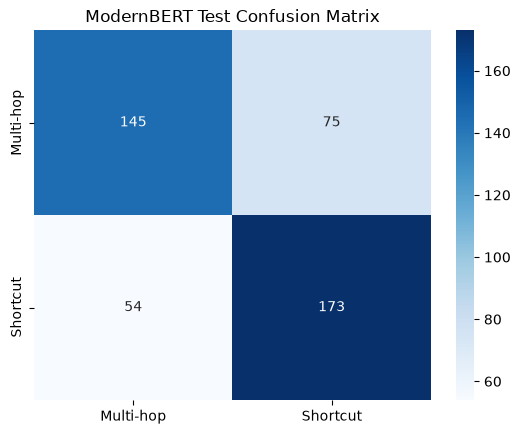

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_curve

# Evaluate on test set
test_pred = trainer.predict(tokenized_datasets['test'])
test_logits = test_pred.predictions
test_labels = test_pred.label_ids
test_preds = np.argmax(test_logits, axis=-1)

print(
    classification_report(
        test_labels, test_preds, target_names=['Multi-hop (0)', 'Shortcut (1)']
    )
)

# Plot Confusion Matrix
cm = confusion_matrix(test_labels, test_preds)
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Multi-hop', 'Shortcut'],
    yticklabels=['Multi-hop', 'Shortcut'],
)
plt.title('ModernBERT Test Confusion Matrix')
plt.show()


In [9]:
# Save final model
SAVE_DIR = '../saved_models/minilm_shortcut_detector'
trainer.save_model(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)


# Inference function
def predict_shortcut(query: str):
  model.eval()
  inputs = tokenizer(
      query, return_tensors='pt', truncation=True, max_length=128
  ).to(device)
  with torch.no_grad():
    logits = model(**inputs).logits
    probs = torch.softmax(logits, dim=-1).cpu().numpy()[0]
    pred = int(np.argmax(probs))
  return {
      'query': query,
      'prediction': id2label[pred],
      'confidence': float(probs[pred]),
      'prob_multihop': float(probs[0]),
      'prob_shortcut': float(probs[1]),
  }


# Test inference
print(
    predict_shortcut(
        "What is the software engineering manager's office room number for the team that built Project Orion?"
    )
)


{'query': "What is the software engineering manager's office room number for the team that built Project Orion?", 'prediction': 'Shortcut', 'confidence': 0.7335191369056702, 'prob_multihop': 0.26648080348968506, 'prob_shortcut': 0.7335191369056702}
